# Türkiye Kentsel Isı Riski: hızlı başlangıç

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ayberkrk/turkiye-heat-risk/blob/main/examples/hizli_baslangic.ipynb)

Bu defter, projenin yayımladığı şehir tablolarını **hiçbir şey kurmadan ve indirmeden** okur: veriler
doğrudan [canlı siteden](https://ayberkrk.github.io/turkiye-heat-risk/) gelir. Gösterilenler:

1. Bir şehrin mahalle tablosunu okumak ve en riskli mahalleleri listelemek
2. Sıralamanın ne kadar sağlam olduğunu belirsizlik sütunlarıyla okumak
3. Riskin sıcaktan mı, kalabalıktan mı geldiğini görmek
4. İlçe karşılaştırması

> Bu endeks bir önceliklendirme aracıdır, sağlık verisiyle doğrulanmamıştır. Skorlar şehir içi görelidir.
> Sütunların anlamı her şehrin `sutun_sozlugu.csv` dosyasında.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

# Veri adresi; yerel bir kopyayla çalışmak için HVI_VERI_ADRESI ortam değişkeni verilebilir.
BASE = os.environ.get("HVI_VERI_ADRESI", "https://ayberkrk.github.io/turkiye-heat-risk")
SEHIR = "izmir"

mahalle = pd.read_csv(f"{BASE}/{SEHIR}/indir/{SEHIR}_mahalleler.csv")
ilce = pd.read_csv(f"{BASE}/{SEHIR}/indir/{SEHIR}_ilceler.csv")
print(f"{len(mahalle)} mahalle, {len(ilce)} ilçe")
mahalle.head(3)

495 mahalle, 18 ilçe


,mahalle_adi,ilce_adi,sira,yol_sayisi,toplam_yol_km,hvi_ort_2020,yuksek_risk_payi_2020,hvi_ort_2026,yuksek_risk_payi_2026,hvi_degisim,...,nufus_yogunlugu,yasli_oran,cocuk_oran,sosyoekonomik_skor,dist_saglik_m,dist_yesil_m,guvenilir_ortalama,sira_medyan,olasilik_ilk_5,olasilik_ilk_20
0,Sarıyer Mahallesi,Karabağlar,1,81,12.0,83.3,1.0,87.0,1.0,3.7,...,30823.9,0.1204,0.1815,1.078,163.2,176.6,Evet,3.0,0.736,0.970
1,Uğur Mumcu Mahallesi,Karabağlar,2,73,10.6,83.8,1.0,86.8,1.0,3.0,...,32884.0,0.1204,0.1815,1.078,270.3,199.3,Evet,3.0,0.792,0.976
2,Umut Mahallesi,Karabağlar,3,87,14.1,83.3,1.0,86.3,1.0,2.9,...,21012.0,0.1204,0.1815,1.078,295.8,630.4,Evet,3.0,0.696,0.978


## 1. En riskli mahalleler

`guvenilir_ortalama == "Evet"`: mahallede en az 20 yol segmenti var, ortalama tek bir yola bağlı değil.

In [2]:
guvenilir = mahalle[mahalle["guvenilir_ortalama"] == "Evet"]
guvenilir[["sira", "mahalle_adi", "ilce_adi", "hvi_ort_2026", "yuksek_risk_payi_2026", "lst_ort_2026"]].head(10)

,sira,mahalle_adi,ilce_adi,hvi_ort_2026,yuksek_risk_payi_2026,lst_ort_2026
0,1,Sarıyer Mahallesi,Karabağlar,87.0,1.0,44.6
1,2,Uğur Mumcu Mahallesi,Karabağlar,86.8,1.0,44.4
2,3,Umut Mahallesi,Karabağlar,86.3,1.0,45.6
3,4,İhsan Alyanak Mahallesi,Karabağlar,84.7,1.0,44.6
4,5,Bozyaka Mahallesi,Karabağlar,84.0,1.0,43.7
5,6,Abdi İpekçi Mahallesi,Karabağlar,84.0,1.0,44.9
6,7,Karabağlar Mahallesi,Karabağlar,82.4,1.0,45.4
7,8,Özgür Mahallesi,Karabağlar,81.8,1.0,45.2
8,9,Gülyaka Mahallesi,Karabağlar,80.8,1.0,43.1
9,10,Göksu Mahallesi,Buca,80.8,1.0,45.2


## 2. Sıralama ne kadar sağlam?

Belirsizlik analizi ağırlık, ölçekleme ve birleştirme kararlarını 500 kez değiştirir. `olasilik_ilk_20`, mahallenin
bu koşularda ilk 20 mahalle arasında kalma oranıdır. Yüksek olasılık, sonucun yöntem tercihlerine bağlı olmadığını gösterir.

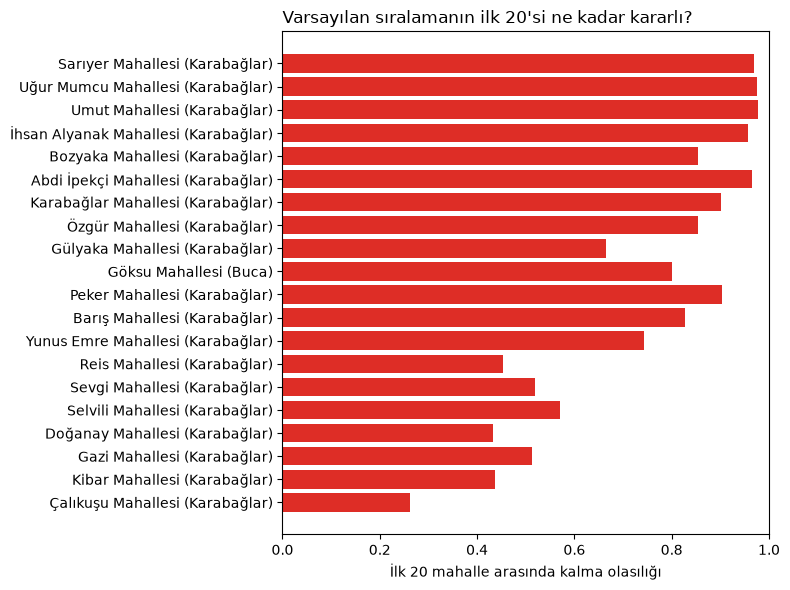

In [3]:
if "olasilik_ilk_20" in mahalle:
    ilk = guvenilir.head(20)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(ilk["mahalle_adi"] + " (" + ilk["ilce_adi"] + ")", ilk["olasilik_ilk_20"], color="#de2d26")
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("İlk 20 mahalle arasında kalma olasılığı")
    ax.set_title("Varsayılan sıralamanın ilk 20'si ne kadar kararlı?", loc="left")
    plt.tight_layout()
    plt.show()

## 3. Risk nereden geliyor?

Yüzey sıcaklığı (°C) ve nüfus yoğunluğu şehirler arasında da karşılaştırılabilen mutlak ölçümlerdir. Sağ üstteki
mahalleler hem sıcak hem kalabalık; renk ortalama HVI.

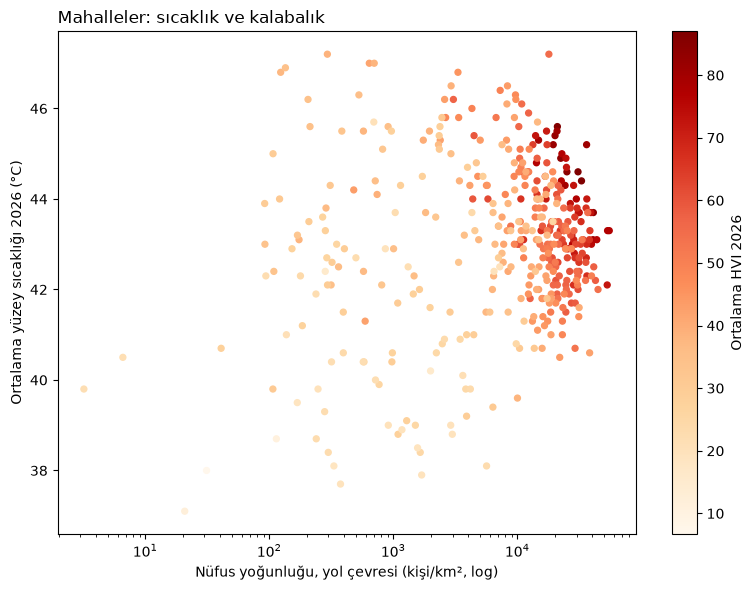

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
noktalar = ax.scatter(guvenilir["nufus_yogunlugu"], guvenilir["lst_ort_2026"], c=guvenilir["hvi_ort_2026"],
                      cmap="OrRd", s=18)
ax.set_xscale("log")
ax.set_xlabel("Nüfus yoğunluğu, yol çevresi (kişi/km², log)")
ax.set_ylabel("Ortalama yüzey sıcaklığı 2026 (°C)")
fig.colorbar(noktalar, label="Ortalama HVI 2026")
ax.set_title("Mahalleler: sıcaklık ve kalabalık", loc="left")
plt.tight_layout()
plt.show()

## 4. İlçeler

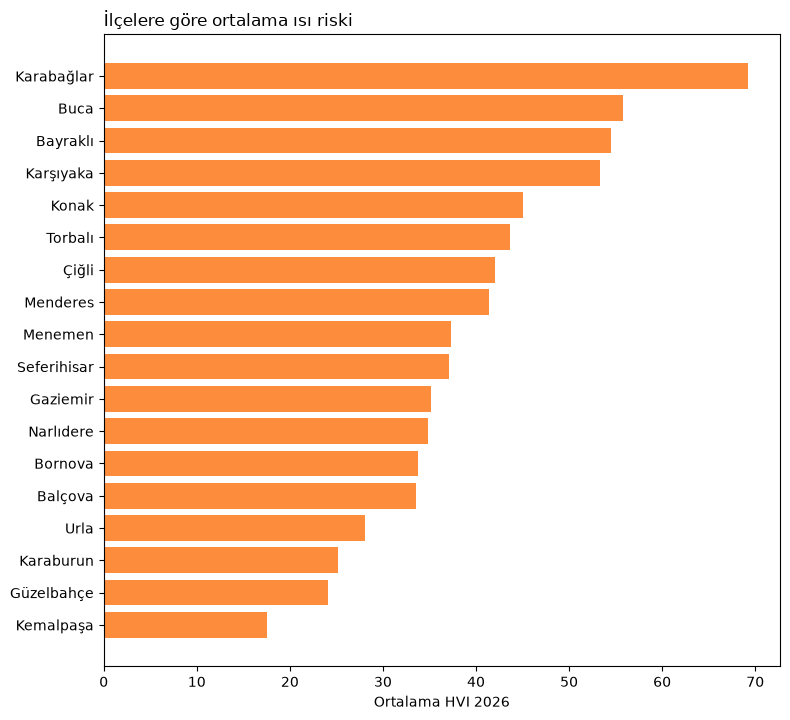

In [5]:
ilce_sirali = ilce.sort_values("hvi_ort_2026")
fig, ax = plt.subplots(figsize=(8, 0.35 * len(ilce_sirali) + 1))
ax.barh(ilce_sirali["ilce_adi"], ilce_sirali["hvi_ort_2026"], color="#fd8d3c")
ax.set_xlabel("Ortalama HVI 2026")
ax.set_title("İlçelere göre ortalama ısı riski", loc="left")
plt.tight_layout()
plt.show()

## Devamı

- Tüm yollar ve mahalle poligonları (GeoPackage): şehrin `*_veri_paketi.zip` dosyası,
  [Releases](https://github.com/Ayberkrk/turkiye-heat-risk/releases/latest).
- Tüm şehirler tek tabloda: `docs/veri/turkiye_mahalleler.csv` (şehirler arası karşılaştırmada yalnızca mutlak sütunları kullanın).
- Yöntem ve sınırlamalar: [README](https://github.com/Ayberkrk/turkiye-heat-risk#readme).